# 1. Contexte métier et problématique

## 1.1 Contexte

TouNum est une entreprise spécialisée dans la numérisation de documents, notamment à partir de supports papier. Dans le cadre de l'augmentation du volume de documents numérisés, l'entreprise souhaite développer de nouveaux services reposant sur les techniques de Machine Learning.

L'un des objectifs du projet consiste à mettre en place une chaîne automatisée permettant d'analyser des images et, à terme, de générer automatiquement une légende descriptive de leur contenu.

Avant de réaliser cette étape de génération de légendes (*image captioning*), une étape de filtrage est nécessaire. En effet, l'ensemble des images numérisées par TouNum ne correspond pas nécessairement à des photographies. Le dataset peut également contenir des schémas, des graphiques, des textes scannés, des dessins ou encore des peintures.

L'objectif de ce premier livrable est donc de développer un modèle de classification capable de distinguer automatiquement :

* les **photographies** ;
* les **autres types d'images**.

Cette classification permettra de sélectionner automatiquement les photographies qui pourront ensuite être transmises aux étapes suivantes du workflow.

## 1.2 Problématique

La problématique étudiée dans ce livrable est donc la suivante :

**Comment développer un modèle de réseau de neurones capable de distinguer automatiquement une photographie d'une autre catégorie d'image dans un ensemble de documents numérisés ?**

La difficulté du problème dépend notamment de la nature des images à distinguer. Les textes scannés ou les schémas présentent généralement des caractéristiques visuelles très différentes des photographies. À l'inverse, certaines peintures possèdent un rendu très réaliste et peuvent donc être visuellement proches d'une photographie.

L'objectif sera ainsi de construire progressivement un modèle, d'évaluer ses performances et d'analyser ses limites afin de déterminer s'il est suffisamment pertinent pour être intégré au workflow de TouNum.


# 2. Objectif de la classification

Le problème est formulé comme une **classification binaire supervisée**.

Deux classes sont retenues :

| Classe | Signification | Exemples                                          |
| ------ | ------------- | ------------------------------------------------- |
| `0`    | Autre         | Schéma, graphique, texte scanné, dessin, peinture |
| `1`    | Photo         | Photographie                                      |

Les datasets fournis par TouNum sont initialement répartis dans différents répertoires selon leur nature. L'absence d'étiquette explicite dans les fichiers ne constitue donc pas un problème : la classe pourra être automatiquement déterminée à partir du répertoire dans lequel se trouve chaque image.

L'objectif final est d'obtenir un modèle capable de prendre une image en entrée et de produire une prédiction binaire :

**Image → Réseau de neurones → Photo / Autre**

Cette première classification constitue une étape de filtrage. Les images identifiées comme des photographies pourront ensuite être transmises aux étapes de traitement d'image et de génération automatique de légendes.


## 3. Importation des librairies

In [71]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pathlib

In [72]:
os.environ['KERAS_BACKEND'] = 'torch'
import keras
from keras import layers
import tensorflow as tf

In [73]:
#pour pouvoir entraîner avec le gpu
print("Active backend:", keras.backend.backend())

Active backend: torch


In [74]:
import torch.cuda as cuda

print(cuda.is_available())
if cuda.is_available():
    print(cuda.get_device_name(0))

True
NVIDIA GeForce RTX 4060 Laptop GPU


## 4. Exploration et visualisation des données du dataset

Commençons tout d'abord par explorer les classes du dataset.


In [75]:
datasets_dir = pathlib.Path('datasets') #D:/datasets

In [76]:
invalid_files = []

for file_path in datasets_dir.rglob("*"):
    if file_path.is_file():
        try:
            content = tf.io.read_file(str(file_path))
            _ = tf.io.decode_image(content, expand_animations=False)
        except tf.errors.InvalidArgumentError as e:
            print(f"Fichier corrompu trouvé : {file_path}")
            print(f"Erreur : {e}\n")
            invalid_files.append((file_path, e))

print(f"{len(invalid_files)} fichier(s) invalide(s)")

for file_path, error in invalid_files:
    print(file_path, "->", error)

0 fichier(s) invalide(s)


In [77]:
for invalid_file in invalid_files:
    invalid_file[0].unlink()

In [78]:
batch_size, img_height, img_width, epochs = 32, 128, 128, 10

In [79]:
def build_datasets(data_dir, batch_size, img_size):
    seed_value = 42

    train_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="training",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    val_and_test_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="validation",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    num_eval_batches = tf.data.experimental.cardinality(val_and_test_ds).numpy()
    val_batches = num_eval_batches // 2

    val_ds = val_and_test_ds.take(val_batches)
    test_ds = val_and_test_ds.skip(val_batches)

    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = build_datasets(datasets_dir, batch_size=batch_size, img_size=(img_height, img_width))

Found 41398 files belonging to 5 classes.
Using 28979 files for training.
Found 41398 files belonging to 5 classes.
Using 12419 files for validation.


In [80]:
labels = train_ds.class_names

class_distribution = {
    label: sum(1 for file in (datasets_dir / label).iterdir() if file.is_file())
    for label in labels
}

print(class_distribution)

{'Painting': 9999, 'Photo': 9993, 'Schematics': 10000, 'Sketch': 1406, 'Text': 10000}


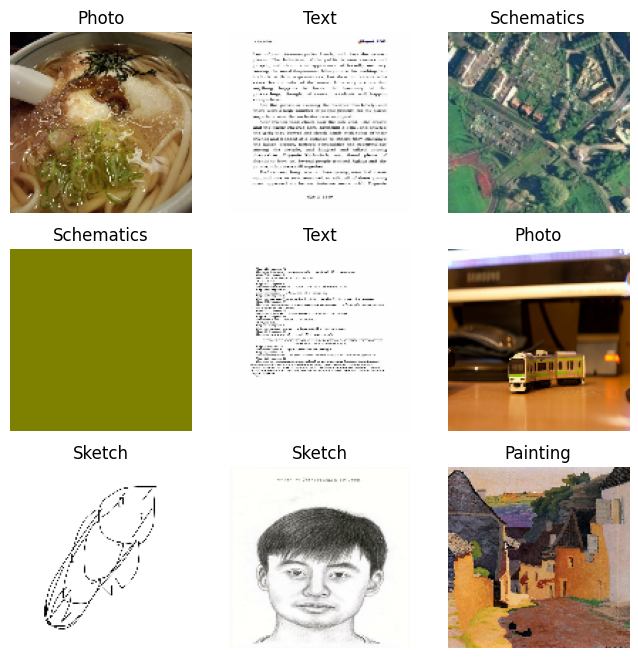

In [81]:
plt.figure(figsize=(8, 8))
for images, label in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i +1)
        ax.imshow(images[i].numpy().astype('uint8'))
        plt.title(labels[label[i]])
        plt.axis("off")

## Chargement des données dans le cache pour optimiser l'entraînement

In [86]:
def normalize_images(images, labels):
    images = images / 255
    return images, labels

In [87]:
AUTOTUNE = tf.data.experimental.AUTOTUNE

train_data = train_ds.map(normalize_images, num_parallel_calls=tf.data.AUTOTUNE).cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_ds.map(normalize_images, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)
test_data = test_ds.map(normalize_images, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)

In [88]:
import psutil
from tqdm import tqdm

process = psutil.Process(os.getpid())

def preload_and_cache(dataset, total_batches, split_name="Dataset"):
    initial_ram = process.memory_info().rss / (1024 ** 2)
    print(f"\n--- Caching {split_name} (RAM before: {initial_ram:.1f} MB) ---")
    
    for _ in tqdm(dataset, total=total_batches, desc=f"Loading {split_name}", unit="batch"):
        pass

    final_ram = process.memory_info().rss / (1024 ** 2)
    delta_ram = final_ram - initial_ram
    print(f"{split_name} cached. RAM used: {final_ram:.1f} MB (+{delta_ram:.1f} MB added)")

preload_and_cache(train_data, len(train_ds), "Train")
preload_and_cache(val_data, len(val_ds), "Validation")
preload_and_cache(test_data, len(test_ds), "Test")


--- Caching Train (RAM before: 5487.9 MB) ---


Loading Train: 100%|██████████| 906/906 [00:41<00:00, 21.93batch/s] 


Train cached. RAM used: 4161.1 MB (+-1326.8 MB added)

--- Caching Validation (RAM before: 4162.3 MB) ---


Loading Validation: 100%|██████████| 194/194 [00:06<00:00, 27.81batch/s]


Validation cached. RAM used: 5289.2 MB (+1126.9 MB added)

--- Caching Test (RAM before: 5289.4 MB) ---


Loading Test: 100%|██████████| 195/195 [00:10<00:00, 19.00batch/s]

Test cached. RAM used: 6959.9 MB (+1670.5 MB added)


## Construction du modèle CNN

Un réseau de neurones convolutif (CNN) est utilisé car il est particulièrement adapté à l'analyse d'images.

Les couches de convolution permettent d'extraire progressivement des caractéristiques visuelles :
- contours ;
- textures ;
- formes ;
- motifs plus complexes.

Les couches de MaxPooling réduisent progressivement la résolution spatiale des représentations tout en conservant les informations les plus importantes.

Une couche Flatten transforme ensuite la représentation multidimensionnelle en vecteur afin de pouvoir utiliser des couches denses pour la classification.

La dernière couche contient un seul neurone associé à une fonction d'activation sigmoïde. Elle produit une probabilité comprise entre 0 et 1 correspondant à la probabilité que l'image appartienne à la classe « Photo ».

In [ ]:
model_baseline = keras.Sequential([

    layers.Input(shape=(img_height, img_width, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(labels), activation="softmax")
])

model_baseline.summary()

model_baseline.compile(optimizer="adam", loss ='sparse_categorical_crossentropy', metrics=['accuracy'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_baseline = model_baseline.fit(
    train_data,
    validation_data=val_data,
    epochs=epochs,
    batch_size=batch_size,
)

c:\Users\arist\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
906/906 ━━━━━━━━━━━━━━━━━━━━ 67s 72ms/step - accuracy: 0.5876 - loss: 0.8751 - val_accuracy: 0.6619 - val_loss: 0.6818
Epoch 2/10
906/906 ━━━━━━━━━━━━━━━━━━━━ 30s 33ms/step - accuracy: 0.7132 - loss: 0.6214 - val_accuracy: 0.7194 - val_loss: 0.6437
Epoch 3/10
906/906 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.7630 - loss: 0.5311 - val_accuracy: 0.7830 - val_loss: 0.5078
Epoch 4/10
906/906 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.7956 - loss: 0.4685 - val_accuracy: 0.8072 - val_loss: 0.4561
Epoch 5/10
906/906 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.8210 - loss: 0.4228 - val_accuracy: 0.8012 - val_loss: 0.4743
Epoch 6/10
906/906 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.8382 - loss: 0.3846 - val_accuracy: 0.8072 - val_loss: 0.4735
Epoch 7/10
906/906 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.8512 - loss: 0.3573 - val_accuracy: 0.7898 - val_loss: 0.5196
Epoch 8/10
906/906 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.8643 - loss: 0.3284 - 

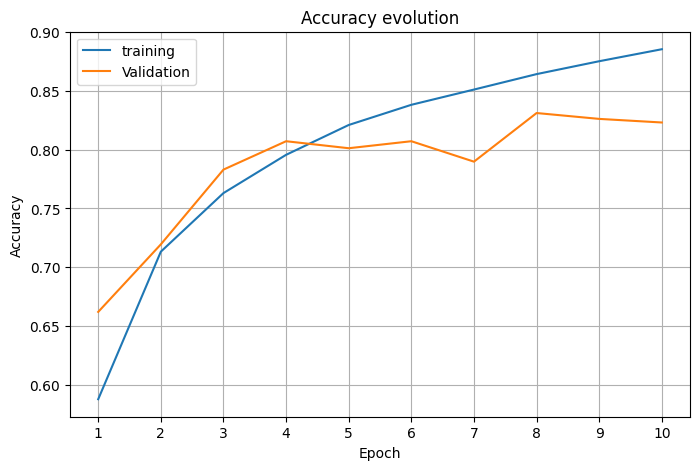

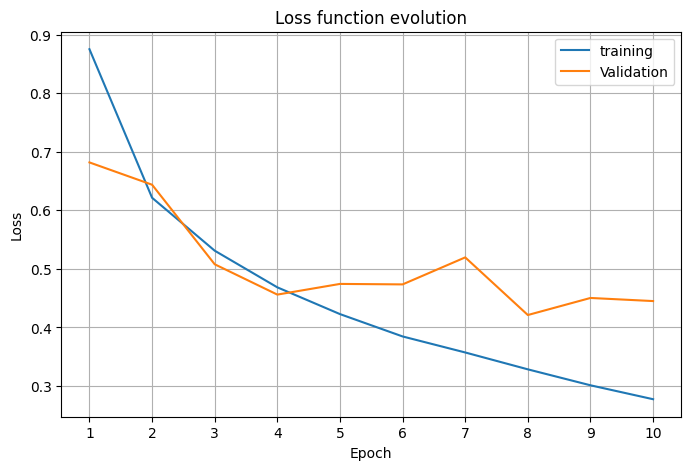

In [ ]:
acc = history_baseline.history["accuracy"]
val_acc = history_baseline.history["val_accuracy"]
loss = history_baseline.history["loss"]
val_loss = history_baseline.history["val_loss"]
actual_epochs = range(1, epochs + 1)

# accuracy plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, acc, label="training")
plt.plot(actual_epochs, val_acc, label="Validation")
plt.title("Accuracy evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# loss plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, loss, label="training")
plt.plot(actual_epochs, val_loss, label="Validation")
plt.title("Loss function evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(f'final training loss: {loss[-1]}\nfinal validation loss: {val_loss[-1]}')
print(f'--- generalization gap: {abs(loss[-1] - val_loss[-1])} ---')
print(f'\nfinal training accuracy: {acc[-1]}\nfinal validation accuracy: {val_acc[-1]}')
print(f'--- accuracy gap: {abs(acc[-1] - val_acc[-1])} ---')

final training loss: 0.2774187922477722
final validation loss: 0.44502758979797363
--- generalization gap: 0.16760879755020142 ---

final training accuracy: 0.8855032920837402
final validation accuracy: 0.8231314420700073
--- accuracy gap: 0.06237185001373291 ---


In [91]:
model_baseline.save('model_baseline.weights.h5')

On peut voir que le modèle est en surapprentissage, nous allons tester différentes techniques pour réduire l'erreur de généralisation


# Influence du batch size sur le modèle
Dans la suite nous allons tester plusieurs taille de batch sur le modèle de base afin de voir son influence sur les résultat de ce dernier. 

In [ ]:
# Définition d'une liste de batch
batch_sizes = [16,32,64,128,256]

In [ ]:
# génération d'un nouveau modèle 
def get_new_model():
    model = keras.Sequential([
    layers.Input(shape=(img_height, img_width, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(labels), activation="softmax")
    ])

    model.compile(optimizer="adam", loss ='sparse_categorical_crossentropy', metrics=['accuracy'])

    return model

In [ ]:
# boucle d'entrainement du modèle avec plusieurs batch

train_losses = {}
val_losses = {}

for bs in batch_sizes:
    train_data, val_data, test_data = build_datasets(datasets_dir, batch_size=bs, img_size=(img_height,img_width))

    #definition du modèle
    model = get_new_model()

    #entrainement du modèle
    history = model.fit(train_data, validation_data=val_data, epochs= 5, verbose=1)
    
    train_losses[bs] = history.history['loss']
    val_losses[bs]=history.history['val_loss']

Found 41398 files belonging to 5 classes.
Using 28979 files for training.
Found 41398 files belonging to 5 classes.
Using 12419 files for validation.


c:\Users\arist\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/5
1812/1812 ━━━━━━━━━━━━━━━━━━━━ 75s 41ms/step - accuracy: 0.7917 - loss: 0.5015 - val_accuracy: 0.8413 - val_loss: 0.3864
Epoch 2/5
1812/1812 ━━━━━━━━━━━━━━━━━━━━ 61s 34ms/step - accuracy: 0.8649 - loss: 0.3341 - val_accuracy: 0.8666 - val_loss: 0.3426
Epoch 3/5
1812/1812 ━━━━━━━━━━━━━━━━━━━━ 86s 47ms/step - accuracy: 0.8932 - loss: 0.2708 - val_accuracy: 0.8906 - val_loss: 0.3030
Epoch 4/5
1812/1812 ━━━━━━━━━━━━━━━━━━━━ 77s 43ms/step - accuracy: 0.9137 - loss: 0.2223 - val_accuracy: 0.8761 - val_loss: 0.3322
Epoch 5/5
1812/1812 ━━━━━━━━━━━━━━━━━━━━ 78s 43ms/step - accuracy: 0.9337 - loss: 0.1723 - val_accuracy: 0.8736 - val_loss: 0.4361
Found 41398 files belonging to 5 classes.
Using 28979 files for training.
Found 41398 files belonging to 5 classes.
Using 12419 files for validation.
Epoch 1/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 65s 71ms/step - accuracy: 0.7666 - loss: 0.5471 - val_accuracy: 0.8355 - val_loss: 0.3923
Epoch 2/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 70s 77ms/step - accuracy: 0

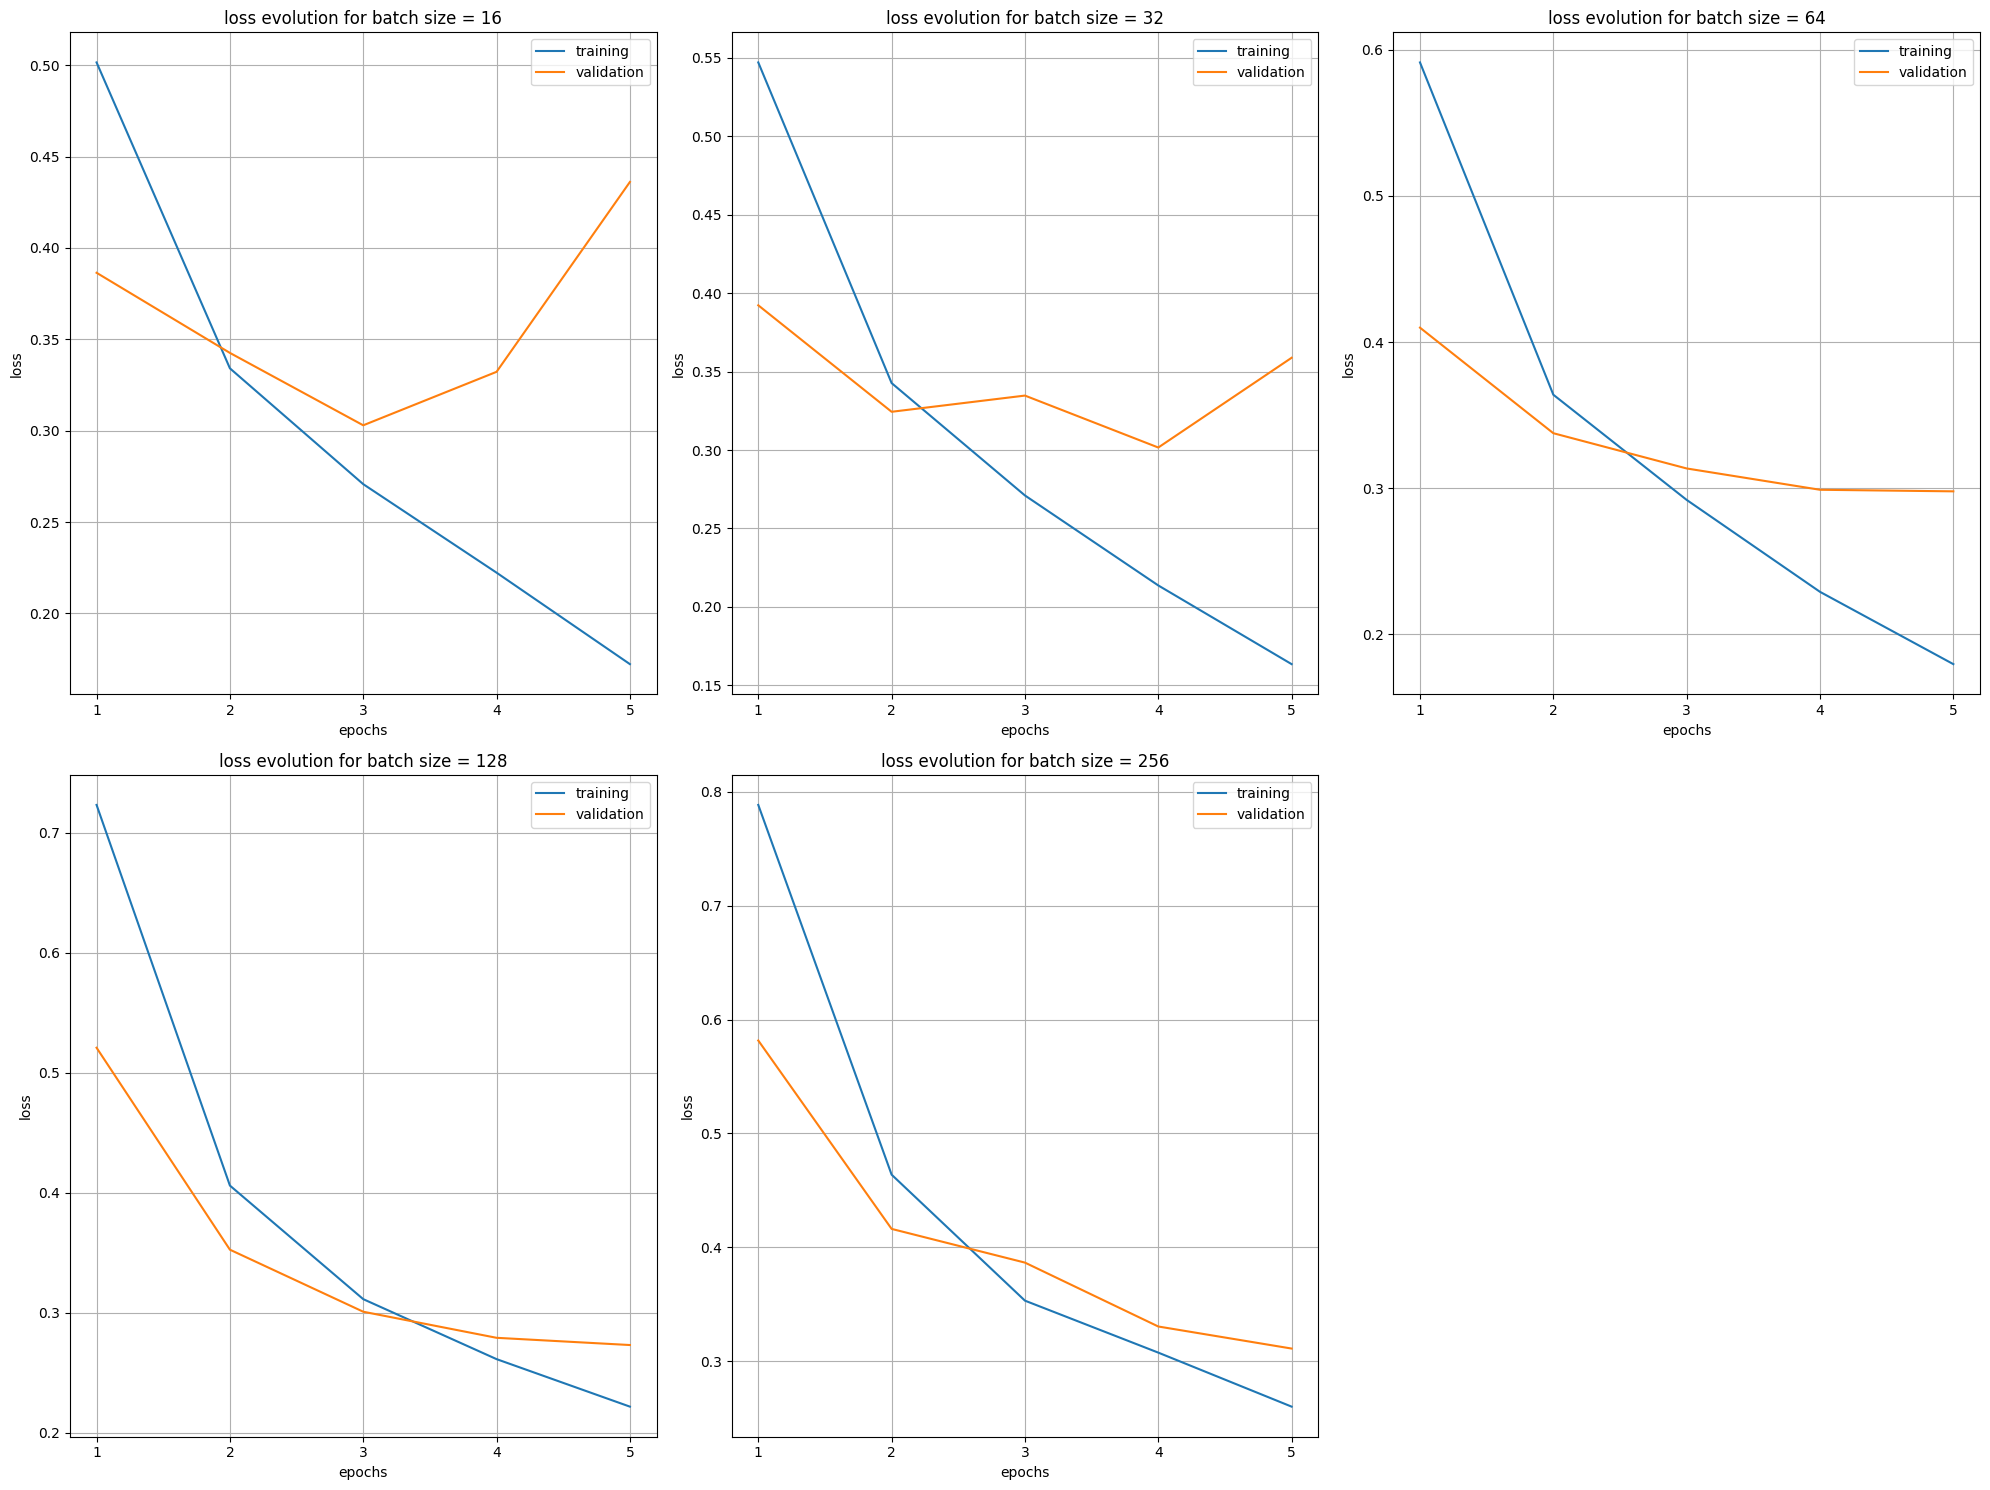

In [ ]:
plt.figure(figsize= (20,15))

for i, bs in enumerate(batch_sizes):
    train_loss = train_losses[bs]
    val_loss = val_losses[bs]
    actual_epochs = range(1, len(train_loss) + 1)
    
    ax = plt.subplot(2, 3, i+1)

    ax.plot(actual_epochs, train_loss, label= "training")
    ax.plot(actual_epochs, val_loss,label="validation") 

    plt.title(f'loss evolution for batch size = {bs}')
    plt.xticks(actual_epochs)
    plt.xlabel('epochs')
    plt.ylabel('loss')
    plt.grid(True)
    plt.legend()
plt.tight_layout()
plt.show()

In [92]:
model.save('model_depending_on_batch.weights.h5')